# How deep was the water?

Reproduces `figures/30_aynuna_bathymetry.png` and `figures/32_soundings_1700.png`.

Two ways at the same question, because no single source covers all seven ports.
Satellites can read the seabed where the water is clear, which in our set means
Leuke Kome and nowhere else. Historic charts carry depth soundings taken by
hand, which is the only option on the Malabar coast.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / 'src'))

import csv
import numpy as np
import matplotlib.pyplot as plt

ROOT = pathlib.Path.cwd().parent
FATHOM = 1.8288   # metres

# Part 1. Satellite bathymetry at Aynuna

Different wavelengths die out at different depths. Red light is gone within a
couple of metres; green reaches perhaps fifteen or twenty in clear water; blue
goes deepest. So the ratio of blue to green rises steadily with depth.

Absorption is exponential with depth, so taking logarithms before dividing
makes the relationship roughly linear. This is Stumpf's method.

It needs clear water over a bright bottom. The Red Sea qualifies; Kerala under
monsoon sediment, the Indus under its plume, and the Rufiji mangroves do not.

In [2]:
from sat import stack

BBOX = [35.10, 27.98, 35.30, 28.16]   # Aynuna bay
med, profile, used = stack.cached_composite('aynuna', BBOX, '2021-01-01', '2024-12-31',
                                            'dry', max_cloud=10, limit=14)
print(f'{len(used)} dry-season scenes')

4 dry-season scenes


### Find the water

The same physical rule as everywhere else: water absorbs near-infrared almost
completely, so `(green - NIR) / (green + NIR)` is positive over water.

In [3]:
green, nir = med['green'], med['nir']
ndwi = (green - nir) / (green + nir + 1e-6)
is_water = ndwi > 0.0
print(f'water covers {100 * np.nanmean(is_water):.0f}% of the box')

water covers 23% of the box


### The depth ratio

One practical fix is needed. In the deepest water the green reflectance falls
so close to zero that its logarithm misbehaves and the ratio explodes, so
reflectance is floored before the division.

In [4]:
FLOOR = 0.002
blue_c = np.clip(med['blue'], FLOOR, None)
green_c = np.clip(green, FLOOR, None)

ratio = np.full(blue_c.shape, np.nan, 'float32')
ok = is_water & np.isfinite(blue_c) & np.isfinite(green_c)
ratio[ok] = np.log(1000 * blue_c[ok]) / np.log(1000 * green_c[ok])

finite = ratio[np.isfinite(ratio)]
print('ratio, 1st / 50th / 99th percentile:', np.percentile(finite, [1, 50, 99]).round(3))
print('higher means deeper, where the bottom is still visible')

ratio, 1st / 50th / 99th percentile: [0.943 1.093 1.231]
higher means deeper, where the bottom is still visible


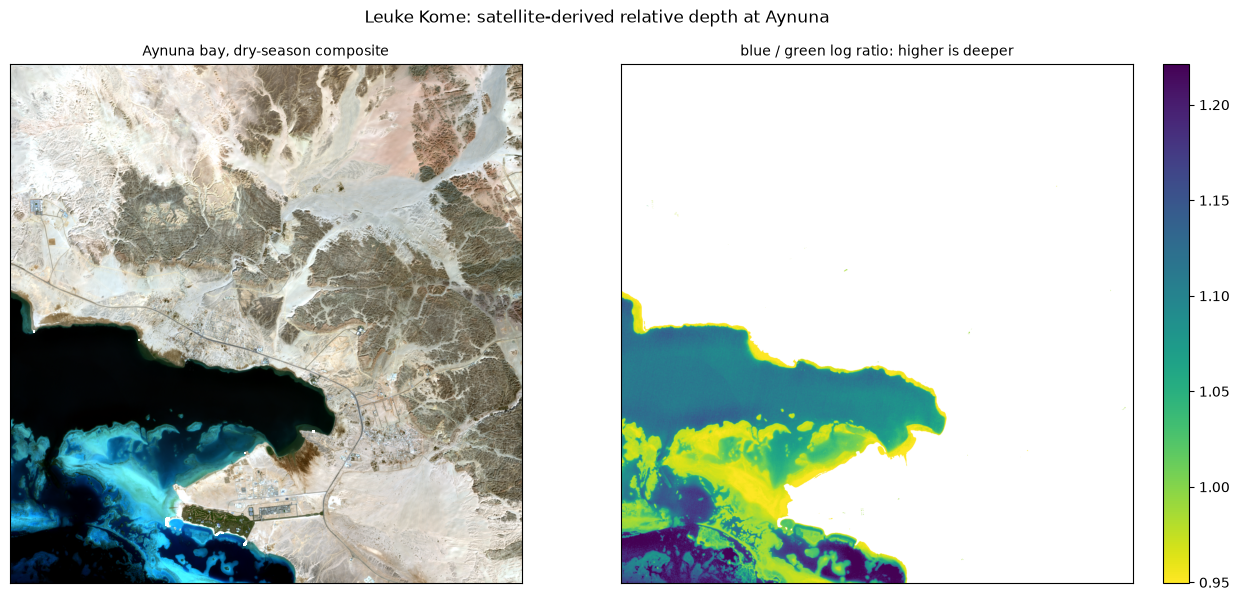

In [5]:
def stretch(a, lo=2, hi=98):
    v = a[np.isfinite(a)]
    p0, p1 = np.percentile(v, [lo, hi])
    return np.clip((a - p0) / (p1 - p0 + 1e-9), 0, 1)

fig, ax = plt.subplots(1, 2, figsize=(13, 6))
ax[0].imshow(np.dstack([stretch(med['red']), stretch(green), stretch(med['blue'])]))
ax[0].set_title('Aynuna bay, dry-season composite', fontsize=10)

shallow = is_water & (green > 0.004)
im = ax[1].imshow(np.where(shallow, ratio, np.nan), cmap='viridis_r',
                  vmin=np.percentile(ratio[shallow], 2),
                  vmax=np.percentile(ratio[shallow], 98))
ax[1].set_title('blue / green log ratio: higher is deeper', fontsize=10)
plt.colorbar(im, ax=ax[1], fraction=.046)
for a in ax:
    a.set_xticks([]); a.set_yticks([])
fig.suptitle('Leuke Kome: satellite-derived relative depth at Aynuna', fontsize=12)
fig.tight_layout()
plt.show()

**Two limits.** This is relative depth, not metres: converting would need known
soundings to calibrate against, and we have none here. And past the depth where
the bottom stops being visible the ratio saturates and means nothing, which I
have not masked. A dark bottom such as seagrass also reads as deep water.

# Part 2. The circa-1700 Dutch chart

On the Malabar coast there is no satellite route, so we read the soundings off
the chart. Twenty of them, transcribed by eye: eleven at the Cranganore
entrance and nine off Purakkad.

Far too few to interpolate a seabed from. Enough for the comparison that
matters, because both were surveyed by the same hand on the same sheet.

**Why that matters.** Historic charts measure depth from different low-water
baselines and often do not say which, so comparing one chart against another
risks reading a baseline difference as silting. Comparing two places on *one*
chart cancels that entirely: whatever the baseline was, it was the same for
both.

In [6]:
rows = list(csv.DictReader(open(ROOT / 'data' / 'raw' / 'soundings_dutch_c1700.csv')))
for r in rows:
    r['metres'] = float(r['fathoms']) * FATHOM

for place in ('Cranganore', 'Purakkad'):
    depths = [r['metres'] for r in rows if r['place'] == place]
    print(f'{place:12s} n={len(depths):2d}   shallowest {min(depths):5.1f} m   '
          f'median {np.median(depths):5.1f} m   deepest {max(depths):5.1f} m')

Cranganore   n=11   shallowest   5.5 m   median  12.8 m   deepest  21.9 m
Purakkad     n= 9   shallowest  11.0 m   median  16.5 m   deepest  21.9 m


### The number that decides it

A ship does not care how deep the harbour is. It cares about the shallowest
point it must cross to get in. A deep basin behind a shallow bar is a shallow
harbour.

At Cranganore the chart draws shoals, banks of sand, right across the entrance,
so the usable depth is whatever the channel between them allows.

In [7]:
entrance = [r['metres'] for r in rows
            if r['place'] == 'Cranganore' and r['setting'] == 'entrance']
purakkad = [r['metres'] for r in rows if r['place'] == 'Purakkad']

print(f'Cranganore entrance, between the shoals: {sorted(entrance)} m')
print(f'shallowest point on the way in:          {min(entrance):.1f} m')
print()
print(f'Purakkad approach, open water:           {min(purakkad):.1f} m at its shallowest')
print()
print('A Roman merchant vessel drew roughly 2.0 to 4.5 m.')

Cranganore entrance, between the shoals: [5.4864, 8.2296, 9.144] m
shallowest point on the way in:          5.5 m

Purakkad approach, open water:           11.0 m at its shallowest

A Roman merchant vessel drew roughly 2.0 to 4.5 m.


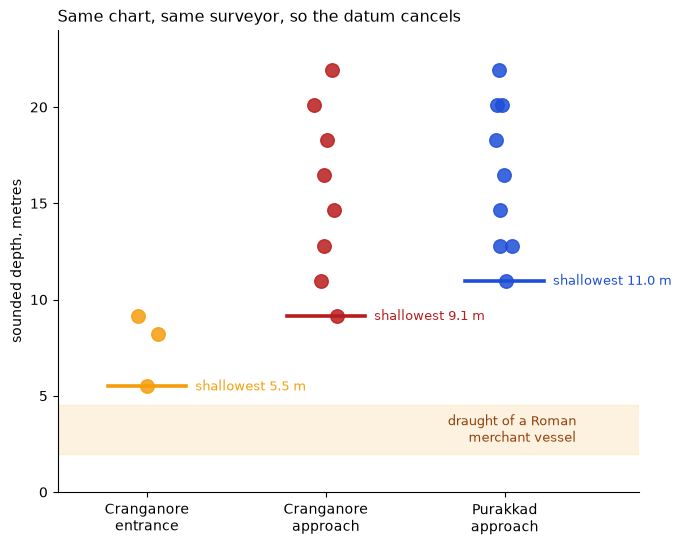

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 6))
groups = [('Cranganore\nentrance', entrance, '#f59e0b'),
          ('Cranganore\napproach',
           [r['metres'] for r in rows if r['place'] == 'Cranganore' and r['setting'] == 'approach'],
           '#b91c1c'),
          ('Purakkad\napproach', purakkad, '#1d4ed8')]

rng = np.random.default_rng(1)
for x, (label, depths, colour) in enumerate(groups):
    ax.scatter(np.full(len(depths), x) + rng.uniform(-.07, .07, len(depths)), depths,
               s=95, color=colour, alpha=.85, zorder=3)
    ax.plot([x - .22, x + .22], [min(depths)] * 2, color=colour, lw=2.6, zorder=4)
    ax.text(x + .27, min(depths), f'shallowest {min(depths):.1f} m', fontsize=9,
            va='center', color=colour)

ax.axhspan(2, 4.5, color='#f59e0b', alpha=.13)
ax.text(2.4, 3.25, 'draught of a Roman\nmerchant vessel', fontsize=9,
        color='#92400e', ha='right', va='center')
ax.set_xticks(range(3)); ax.set_xticklabels([g[0] for g in groups], fontsize=10)
ax.set_ylabel('sounded depth, metres', fontsize=10)
ax.set_ylim(0, 24); ax.set_xlim(-.5, 2.75)
ax.spines[['top', 'right']].set_visible(False)
ax.set_title('Same chart, same surveyor, so the datum cancels', fontsize=11.5, loc='left')
plt.show()

## Result, and what it does not say

The Cranganore entrance shoals to 5.5 m between drawn sand banks. Purakkad's
approach holds 11 m and is open.

But both clear a laden merchantman. So the chart does **not** show Cranganore
closed in 1700. It shows it constricted: half the depth, squeezed between
banks, against an open approach sixty kilometres south.

That is the direction Pliny points when he calls Bakare *alius utilior portus*,
a more useful port than Muziris. It is weaker than saying the harbour silted up,
and it is seventeen centuries after the Periplus.